In [18]:
import numpy as np
import scipy as sp
import xarray as xr
import seaborn as sea
import matplotlib.pyplot as plt
import cartopy 
import cmocean 
import cartopy.crs as ccrs 
import cartopy.feature as cfeature

In [2]:
import sys 
import os 
sys.path.append(os.path.abspath('/lustre/storeB/project/fou/hi/foccus/malene/ocean-ai/plot/master/statistics/'))
from dataloader_inf import open_dataset
helper_ses = sys.path.append(os.path.abspath('/lustre/storeB/project/fou/hi/foccus/malene/ocean-ai/plot/master/'))
from seasonal_util import seasons

In [3]:
#NK 
nk_path = '/lustre/storeB/project/fou/hi/foccus/malene/ocean-ai/plot/master/statistics/saved_nc'
nk_year = xr.open_dataset(f'{nk_path}/yearly_average.nc')
nk_month = xr.open_dataset(f'{nk_path}/monthly_average.nc')
#HB
hb_path = '/lustre/storeB/project/fou/hi/foccus/malene/run-ocean-anemoi/ppi/external_checkpoint_inference/results/rollout_benchmark_lr3.5e6-rs3-i0-m3/step_51000_e14/resampled_means'
hb_year = open_dataset(f'{hb_path}/yearly_mean.nc').ds
hb_month = open_dataset(f'{hb_path}/monthly_mean.nc').ds

In [4]:
nk_ses = seasons(nk_month)
hb_ses = seasons(hb_month)

<xarray.DataArray 'days_in_month' (time: 12)> Size: 96B
array([31, 29, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31])
Coordinates:
    s_rho    float64 8B ...
    s_w      float64 8B ...
  * time     (time) datetime64[ns] 96B 2024-01-01 2024-02-01 ... 2024-12-01
Attributes:
    long_name:      time since initialization
    field:          time, scalar, series
    axis:           T
    standard_name:  time
<xarray.DataArray 'days_in_month' (time: 13)> Size: 104B
array([31, 29, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31, 31])
Coordinates:
  * time     (time) datetime64[ns] 104B 2024-01-01 2024-02-01 ... 2025-01-01


In [5]:
#import fh contours py
helper3 = helper_ses = sys.path.append(os.path.abspath('/lustre/storeB/project/fou/hi/foccus/malene/ocean-ai/plot'))
from fh_script import *

In [6]:
mean_uvel_n = nk_ses.u_eastward
mean_vvel_n = nk_ses.v_northward
mean_uvel_h = hb_ses.u_eastward
mean_vvel_h = hb_ses.v_northward

In [7]:
#miiip jeg har droppa f og h i resamplingene, men det skal være konstante verdier så per nå er det kanskje lettere å hente de og legge de på manuelt
norkyst_gen_path = '/lustre/storeB/project/fou/hi/foccus/datasets/symlinks/norkystv3-hindcast/2024/'
#choose all
import glob
filenames = glob.glob(f'{norkyst_gen_path}/*.nc')
ds = xr.open_mfdataset(filenames, engine = 'netcdf4').isel(s_rho = -1, s_w = -1)

In [8]:
ds_monthly_h_nk = ds.h.resample(time = 'MS').mean().compute()

In [9]:
season_h_norkyst = seasons(ds_monthly_h_nk)

<xarray.DataArray 'days_in_month' (time: 12)> Size: 96B
array([31, 29, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31])
Coordinates:
    s_rho    float64 8B -0.004904
    s_w      float64 8B 0.0
  * time     (time) datetime64[ns] 96B 2024-01-01 2024-02-01 ... 2024-12-01
Attributes:
    long_name:      time since initialization
    field:          time, scalar, series
    axis:           T
    standard_name:  time


In [11]:
#because h is a norkyst forcing in HB, I believe we can use the same H! Change this if not
#calculate f manually - the same domain for HB and NK here as well

omega = 7.2921e-5
lat_nor = nk_ses.lat
lat_nor_rad = np.deg2rad(lat_nor)
f_nor = 2 * omega * np.sin(lat_nor_rad)

In [ ]:
#now lets do f_h per season
fh_DJF = f_nor.values / season_h_norkyst.sel(season = 'DJF')
fh_JJA = f_nor.values / season_h_norkyst.sel(season = 'JJA')
fh_MAM = f_nor.values / season_h_norkyst.sel(season = 'MAM')
fh_SON = f_nor.values / season_h_norkyst.sel(season = 'SON')

In [47]:
def fh_norkyst(area, fh, u_vel, v_vel, title, szn, step = 5, min_l = -0.5e-5, max_l = 1.44e-5):

    """
    Definition:
    A function for plotting the f/h contours for the Norkyst files. 

    Arguments:
    arg[1] - Area (dataset) - named area because the chosen area to plot must be cut out before passing the dataset. 
    arg[2] - title (str) - title of the Figure
    arg[3] - Save_path (str) - path to save the Figure. Please enter full path.

    Returns:
    A plot saved as a png Figure.
    """

    fig, ax = plt.subplots(figsize = (10,12), subplot_kw={'projection' : ccrs.NorthPolarStereo()})
    ax.set_facecolor('lightgray')
    #ax.set_alpha(1)
    step = step
    min_l = min_l
    max_l = max_l
    custom = np.linspace(min_l, max_l, 20)
    im = ax.contour(area.lon.values, area.lat.values, fh[:,:], levels = custom, transform = ccrs.PlateCarree(), zorder = 2, color = 'black')
    im_fill = ax.contourf(area.lon.values, area.lat.values, fh[:,:], levels = custom, transform = ccrs.PlateCarree(), zorder = 1, cmap = cmocean.cm.topo)
    ax.quiver(area.lon.values[::step, ::step], area.lat.values[::step, ::step], u_vel[szn,:,:].values[::step, ::step], v_vel[szn,:,:].values[::step, ::step], transform = ccrs.PlateCarree(), color = 'black', alpha = 0.6, scale = 30)
    cax = fig.add_axes([ax.get_position().x1+0.025, ax.get_position().y0, 0.025, ax.get_position().height])
    cbar = fig.colorbar(im_fill, ax=ax, cax = cax, extend = 'both')
    cbar.ax.set_title(r'$\frac{f}{h}$')
    gl = ax.gridlines(crs = ccrs.PlateCarree(), draw_labels = True, linewidth = 1, color = 'black', alpha = 0.1, linestyle = '--')
    #ax.add_feature(cfeature.OCEAN, edgecolor = 'black', facecolor = 'lightblue', alpha = 0.4)
    ax.add_feature(cfeature.LAND, edgecolor='black', facecolor='lightgray', alpha =0.4)
    gl.xlabels_top = False 
    gl.ylabels_right = False 
    ax.set_title(f'{title}')
    plt.show()

In [35]:
DJF_nk = nk_ses.sel(season = 'DJF')
JJA_nk = nk_ses.sel(season = 'JJA')
MAM_nk = nk_ses.sel(season = 'MAM')
SON_nk = nk_ses.sel(season = 'SON')

DJF_hb = hb_ses.sel(season = 'DJF')
JJA_hb = hb_ses.sel(season = 'JJA')
MAM_hb = hb_ses.sel(season = 'MAM')
SON_hb = hb_ses.sel(season = 'SON')

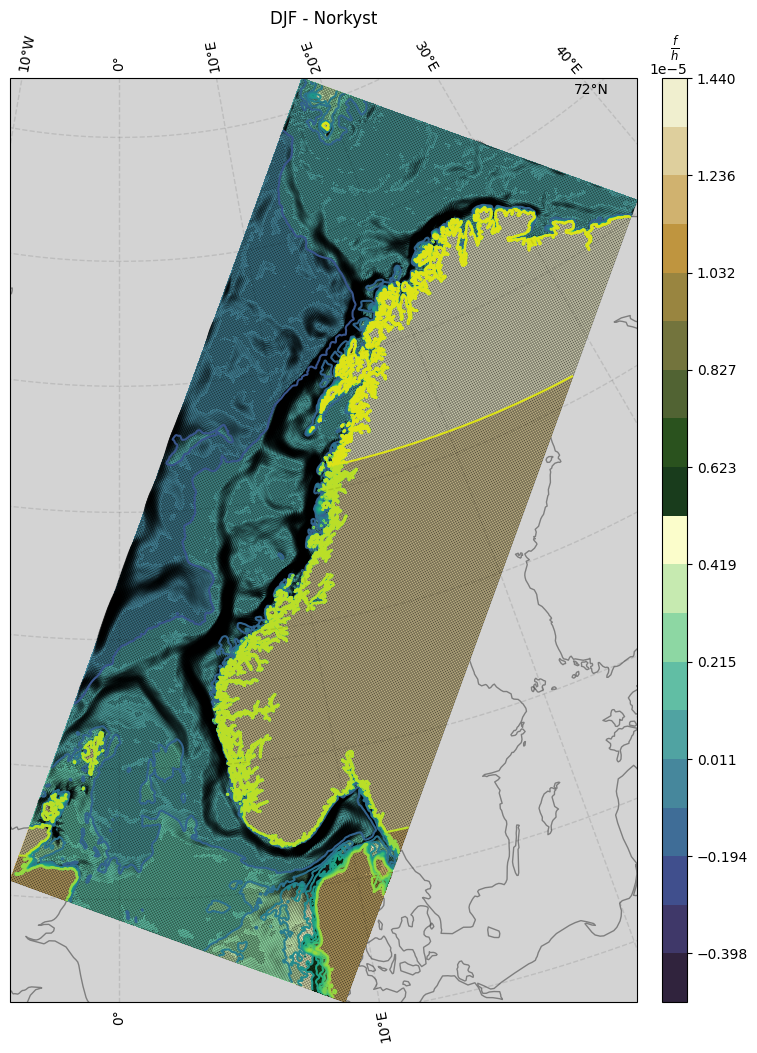

In [48]:
fh_norkyst(DJF_nk, fh_DJF, mean_uvel_n, mean_vvel_n, title = 'DJF - Norkyst', szn = 0, step = 5, min_l = -0.5e-5, max_l = 1.44e-5)

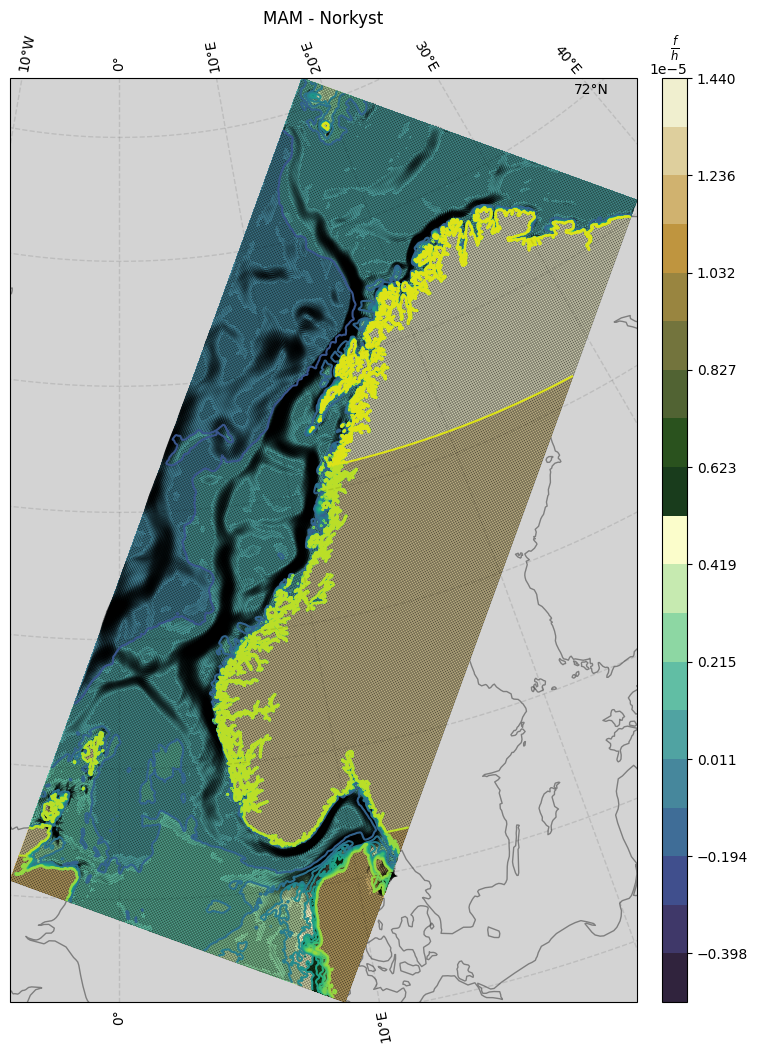

In [49]:
fh_norkyst(MAM_nk, fh_MAM, mean_uvel_n, mean_vvel_n, title = 'MAM - Norkyst', szn = 1, step = 5, min_l = -0.5e-5, max_l = 1.44e-5)


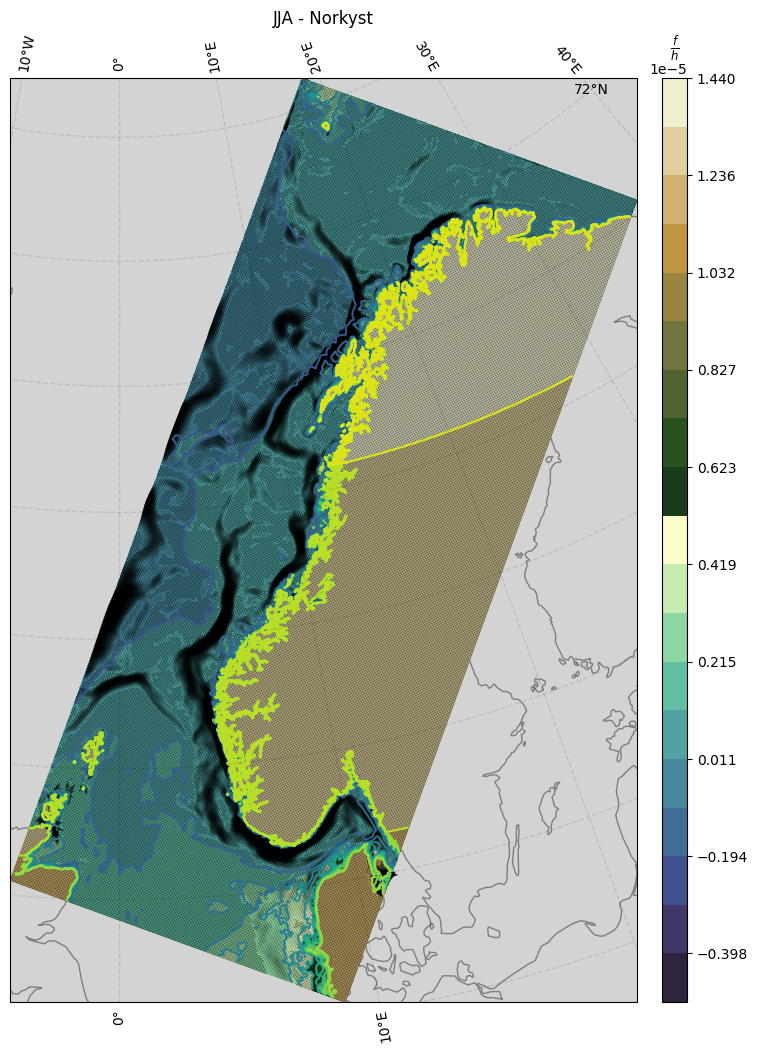

In [50]:
fh_norkyst(JJA_nk, fh_JJA, mean_uvel_n, mean_vvel_n, title = 'JJA - Norkyst', szn = 2, step = 5, min_l = -0.5e-5, max_l = 1.44e-5)


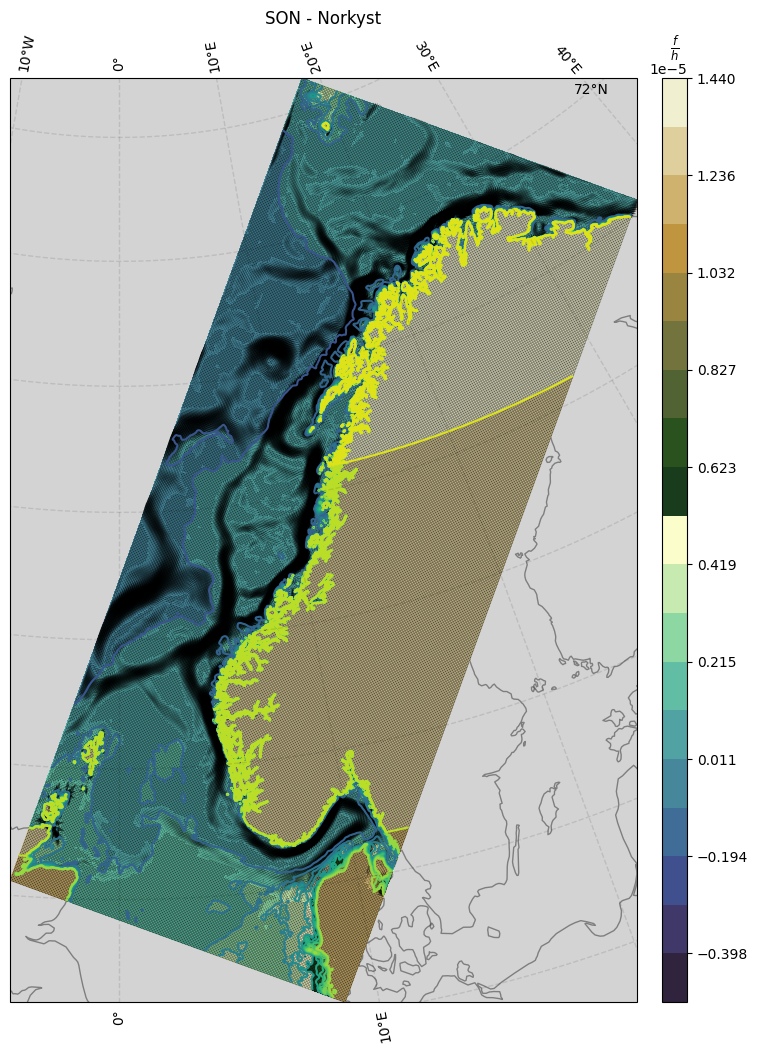

In [51]:
fh_norkyst(SON_nk, fh_SON, mean_uvel_n, mean_vvel_n, title = 'SON - Norkyst', szn = 3, step = 5, min_l = -0.5e-5, max_l = 1.44e-5)


In [ ]:
fh_norkyst(DJF_hb, fh_DJF, mean_uvel_h, mean_vvel_h, title = 'DJF - Havbris', szn = 0, step = 5, min_l = -0.5e-5, max_l = 1.44e-5)

In [ ]:
fh_norkyst(MAM_hb, fh_MAM, mean_uvel_h, mean_vvel_h, title = 'MAM - Havbris', szn = 1, step = 5, min_l = -0.5e-5, max_l = 1.44e-5)

In [ ]:
fh_norkyst(JJA_hb, fh_JJA, mean_uvel_h, mean_vvel_h, title = 'JJA - Havbris', szn = 2, step = 5, min_l = -0.5e-5, max_l = 1.44e-5)

In [ ]:
fh_norkyst(SON_hb, fh_SON, mean_uvel_h, mean_vvel_h, title = 'SON - Havbris', szn = 3, step = 5, min_l = -0.5e-5, max_l = 1.44e-5)